In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# KNN

## Titanic
Vamos a crear un modelo que prediga la probabilidad de supervivencia de los pasajeros

https://www.kaggle.com/c/titanic/data?select=train.csv

0. Importar data de training y testing. Agregarle a la tabla de testing la columna survived proveniente de la tabla gender_submission

In [2]:
data_test = pd.read_csv(r"C:\Users\millo\OneDrive\MASTER NEOLAND\Ejercicio_practico_KNN\Titanic\test.csv")
data_train = pd.read_csv(r"C:\Users\millo\OneDrive\MASTER NEOLAND\Ejercicio_practico_KNN\Titanic\train.csv")
data_gender_submission = pd.read_csv(r"C:\Users\millo\OneDrive\MASTER NEOLAND\Ejercicio_practico_KNN\Titanic\gender_submission.csv")

In [3]:
# Prueba:
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
# NOTA: Recuerda que tenemos que encontrar la columna Key que las une para poder hacer el merge, y esa columna es PassengerID.

data_test = data_test.merge(
    data_gender_submission[["PassengerId", "Survived"]],
    on = "PassengerId"
)


In [5]:
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,1


1. Buscar columnas con valores nulos y cantidad de nulos en cada una. Fijarse el porcentaje de los datos nulos que representan sobre el total.

In [6]:
# Paso 1: Contar los nulos de cada columna.
data_train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [7]:
# El .isnull() identifica los valores NaN y el .sum() los cuenta por columna.

In [8]:
# Paso 2: Sacar el porcentaje que de datos nulos que afectan a la información:
data_train.isnull().sum() / len(data_train) * 100

PassengerId     0.000000
Survived        0.000000
Pclass          0.000000
Name            0.000000
Sex             0.000000
Age            19.865320
SibSp           0.000000
Parch           0.000000
Ticket          0.000000
Fare            0.000000
Cabin          77.104377
Embarked        0.224467
dtype: float64

In [9]:
 # NOTA: len(data_train) → cantidad total de filas.

2. En base al resultado anterior. Cuales columnas consideran que tienen sentido completar y cuales se deberían eliminar? Eliminar la que corresponda de la tabla de test y de train.

In [10]:
# A ver, esta es un pregunta un poco trampa, porque en realidad eliminar columnas no tiene tanto que ver solamente con la cantidad
# de datos nulos que podamos encontrar, sino que on información que nos vale madre y que sobra porque es irrelevante  y solamente
# ocupa datos de memoria.

# Así que yo eliminaría lo siguiente:

# 1.- Name (Todos son diferentes)
# 2.- PassengerId
# 3.- Ticket
# 4.- Cabin

# Por falta de datos yo completaría calculando los restantes:

# 1.-Age
# 2.-Embarked

3. Completar valores nulos con el criterio que considres correcto en cada una de las columnas (que tengan sentido completar). Esto debe hacerse tanto en la tabla de training como la de testing (con el mismo criterio en ambas).

   Verificar como se distribuyen los valores de cada columna con un gráfico previamente para tener más herramientas en la decisión

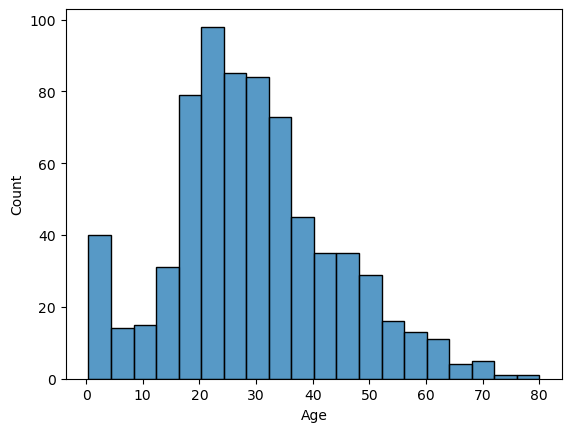

In [11]:
# Paso 1.- Tenemos que graficar los valores de Age y Embarked como dice el enunciado para poder tomar mejores decisiones.

sns.histplot(data = data_train, x = "Age")
plt.show()

In [12]:
# NOTA: Esto nos permitirá ver si Age tiene una distribución aproximadamente simétrica o si está sesgada.
# A partir de ese gráfico decidiremos si conviene usar la media o la mediana para completar los valores nulos.

# Aqui para "age´" la decisión importante: Usar la mediana para completar los datos:

data_train["Age"].median()

# Salió 28 entonces rellenamos los valores con el 28 que es la mediana.

data_train["Age"] = data_train["Age"].fillna(28)
data_test["Age"] = data_test["Age"].fillna(28)

# Comprobamos:ç

data_train["Age"].isnull().sum()
data_test["Age"].isnull().sum()

# 1.- Media: sumar todos los valores y dividir entre la cantidad.
# 2.- Mediana: ordenar los valores y tomar el valor central.
# 3.- Moda: Es el valor que más se repite en un conjunto de datos.

np.int64(0)

In [13]:
# Análisis propio:
# En este caso sacar la media o la mediana sería casi lo mismo, ¿no? Porque ahí en las orillas hay muy pocos valores.Solo veo que de 0 a 5 es la única barra
# que brinca demasiado y que podría modificar lo que llamamos, dispersión.

# Entendiendo que el resultado puede ser mas o menos parecido, creo que optaré por la mediana, porque esa barra puede jalar
# mis valores un poco hacia abajo y la mediana no, porque es donde se concentra la mayor parte de los datos representativos.

<Axes: xlabel='Embarked'>

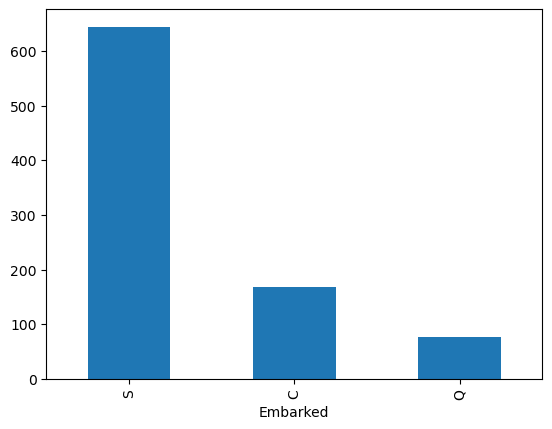

In [14]:
# Para embarked no se puede graficarun histograma, sino que necesitamos ver cuántas clasificaciones de pasajeros en embarked hay,
# por ello vamos a hacer una gráfica de barras.

data_train["Embarked"].value_counts().plot(kind="bar")

In [15]:
# La diferencia es:

# Age → histograma → porque es una variable numérica continua.
# Embarked → gráfico de barras → porque es una variable categórica (S, C, Q).

In [16]:
# SIGUIENTE Analizar la gráfica de Embarked y decidir cómo rellenar sus nulos.

# Eligiremos rellenar con la moda porque tiene sentido utilizar la etiqueta más frecuente.

In [17]:
data_train["Embarked"].mode()

0    S
Name: Embarked, dtype: object

In [18]:
# Ahora queremos rellenar los nulos de Embarked tanto en data_train como en data_test con S
# Primero lo hacemos en train:

data_train["Embarked"] = data_train["Embarked"].fillna("S")

# Comprobamos: 
data_train["Embarked"].isnull().sum()


np.int64(0)

In [19]:
# Ahora en test:
data_test["Embarked"] = data_test["Embarked"].fillna("S")

# Comprobamos: 
data_test["Embarked"].isnull().sum()

np.int64(0)

4. Realizar análisis exploratorio. Graficar las personas que sobrevivieron por:
    - Clase (Pclass)
    - Sexo (Sex)
    - Costo de boleto (Fare)

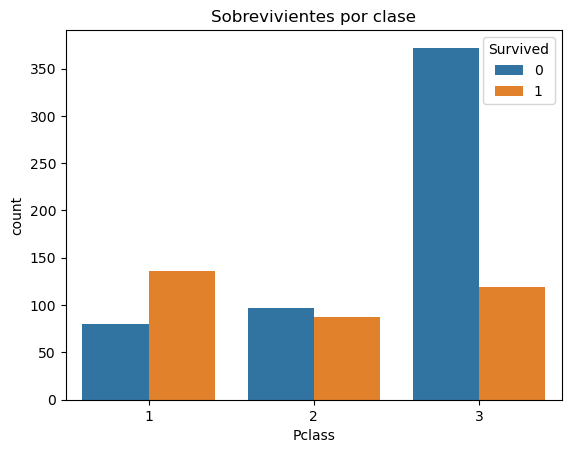

In [20]:
# Paso 1.- Sobrevivientes por clase

# Como Pclass es una variable categórica/discreta (1, 2 y 3), podemos usar un gráfico de barras:

sns.countplot(data=data_train, x="Pclass", hue="Survived")
plt.title("Sobrevivientes por clase")
plt.show()

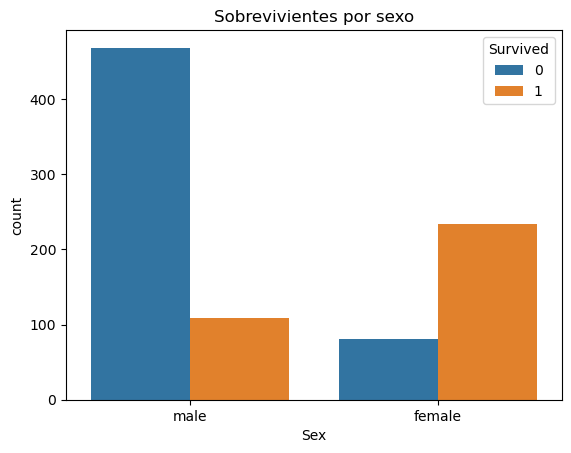

In [21]:
# Paso 2.- 2. Sobrevivientes por sexo
# Ahora hacemos lo mismo, cambiando Pclass por Sex:

sns.countplot(data=data_train, x="Sex", hue="Survived")
plt.title("Sobrevivientes por sexo")
plt.show()

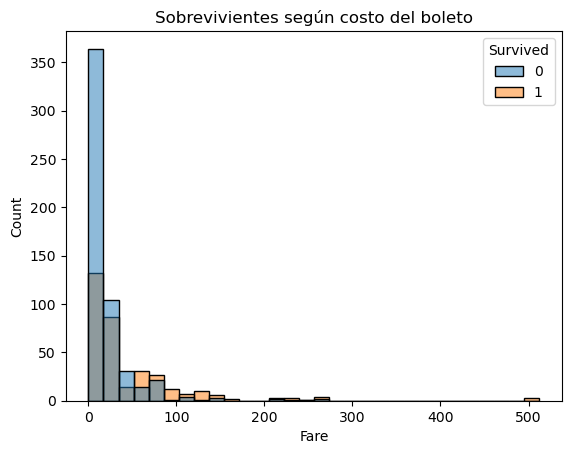

In [22]:
# Paso 3.- Sobrevivientes según el costo del boleto (Fare)
# Aquí cambia la cosa: Fare es numérica continua, así que usamos un histograma.

sns.histplot(data=data_train, x="Fare", hue="Survived", bins=30)
plt.title("Sobrevivientes según costo del boleto")
plt.show()

5. Verificar columnas del DataFrame e identificar sobre cuales se deberían generar variables dummies.
   Generar columnas de dummies sobre "Pclass","Embarked" y "Sex". Aplicar cambios en training y testing

In [23]:
# Nota recordatorio: 
# Las variables dummies sirven para convertir palabras/categorías en números, porque los modelos de Machine Learning trabajan mejor con números. (0 y 1)
# Aquí hay algo curioso, y es que en la columna PC Class ya viene en números, sin embargo en este caso, se tienen que entender como categorías, no como valores,
# o sea, 1 está haciendo referencia a primera clase , 2 a segunda y 3 a tercera, por ello hay que convertirlos a dummies.

In [24]:
# Paso 1.- Verificar columnas:

data_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [25]:
data_test.columns

Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked', 'Survived'],
      dtype='object')

In [26]:
# PAso 2.- Vamos a generar las dummies primero en data_train, y después haremos exactamente lo mismo en data_test.Para ello utilizaremos      pd.get_dummies().
# pd.get_dummies() Agarra una columna con categorías y crea una columna 0/1 para cada categoría.

In [27]:
pd.get_dummies(data_train["Sex"])

,female,male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True
...,...,...
886,False,True
887,True,False
888,True,False
889,False,True


In [28]:
# Es decir:

# True → pertenece a esa categoría
# False → no pertenece
# Por ejemplo, e la primera fila:
# Es Male → entonces male = 1 → sí pertenece
# No es Female → entonces female = 0 → no pertenece


In [29]:
# Ahora ya que están creadas las dummies y que me las ha mostrado (True y False), vamos a aplcarlas a data_train primero

dummies_sex = pd.get_dummies(data_train["Sex"])

In [30]:
# Verificar que se crearon las columnas:
dummies_sex.head()

,female,male
0,False,True
1,True,False
2,True,False
3,True,False
4,False,True


In [31]:
# Ahora tenemos que aplicar estos cambios "dummies_sex. a train y test.
# Siguiente paso: añadir las dummies a data_train

data_train = pd.concat([data_train, dummies_sex], axis=1)

# Lo que "vendría siendo" : Coge data_train y añádele las columnas de dummies_sex al lado.
# Esta mierda duplicó las columnas con el concat, por ello tengo que eliminar duplicados con la siguiente línea de código.

data_train = data_train.loc[:, ~data_train.columns.duplicated()]

# Comprobamos:
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,female,male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,True


In [32]:
data_train = data_train.loc[:, ~data_train.columns.duplicated()]
data_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,female,male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,False,True
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,True,False
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,NaN,S,True,False
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,False,True


In [33]:
# Aplicar las dummies para Data_test.
dummies_sex_test = pd.get_dummies(data_test["Sex"])
dummies_sex_test.head()


,female,male
0,False,True
1,True,False
2,False,True
3,False,True
4,True,False


In [34]:
# Ya tenemos los dummies, pero ahora hay que agregarlos al dataframe data_test.
data_test = pd.concat([data_test, dummies_sex_test], axis=1)
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,female,male
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0,False,True
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1,True,False
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0,False,True
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0,False,True
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,1,True,False


In [35]:
# Ahora convertimos PC_class a dummies.
dummies_pclass = pd.get_dummies(data_train["Pclass"])
dummies_pclass.head()

,1,2,3
0,False,False,True
1,True,False,False
2,False,False,True
3,True,False,False
4,False,False,True


In [36]:
# Siguiente paso: 
# Ahora hacemos con Pclass lo mismo que hicimos con Sex: añadir las dummies a data_train.
data_train = pd.concat([data_train, dummies_pclass], axis=1)
data_train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,female,male,1,2,3
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,False,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,False,True,False,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,True,False,False,True


In [37]:
# NOTA: en este caso, en la primera fila es un hombre de tercera clase, si no me equivoco.

In [38]:
# Siguiente paso:

# Ahora toca Embarked, que representa el puerto donde embarcó el pasajero.
# Sabemos que sus categorías son:
# S → Southampton
# C → Cherbourg
# Q → Queenstown

In [39]:
# Crear las dummies en data_train

dummies_embarked = pd.get_dummies(data_train["Embarked"])
dummies_embarked.head()

# Ahora añadirlas con concat:
data_train = pd.concat([data_train, dummies_embarked], axis=1)
data_train


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,female,male,1,2,3,C,Q,S
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,True,False,False,True,False,False,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,False,True,False,False,True,False,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,True,False,False,False,True,False,False,True
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,False,True,False,False,False,False,True
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,True,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,False,True,False,True,False,False,False,True
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,True,False,True,False,False,False,False,True
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,28.0,1,2,W./C. 6607,23.4500,NaN,S,True,False,False,False,True,False,False,True
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,False,True,True,False,False,True,False,False


In [40]:
# Ahora crear dummies pa data_test
dummies_pclass_test = pd.get_dummies(data_test["Pclass"])
dummies_pclass_test

,1,2,3
0,False,False,True
1,False,False,True
2,False,True,False
3,False,False,True
4,False,False,True
...,...,...,...
413,False,False,True
414,True,False,False
415,False,False,True
416,False,False,True


In [41]:
# Añadir las columnas a test
data_test = pd.concat([data_test, dummies_pclass_test], axis=1)
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,female,male,1,2,3
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0,False,True,False,False,True
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1,True,False,False,False,True
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0,False,True,False,True,False
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0,False,True,False,False,True
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,1,True,False,False,False,True


In [42]:
# Las dupliqué por pendejo de nuevo con concat
data_test = data_test.loc[:, ~data_test.columns.duplicated()]
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,female,male,1,2,3
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0,False,True,False,False,True
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1,True,False,False,False,True
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0,False,True,False,True,False
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0,False,True,False,False,True
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,1,True,False,False,False,True


In [43]:
# Siguiente paso:  Nos falta solo Embarked en data_test.
dummies_embarked_test = pd.get_dummies(data_test["Embarked"])
dummies_embarked_test.head()

,C,Q,S
0,False,True,False
1,False,False,True
2,False,True,False
3,False,False,True
4,False,False,True


In [44]:
data_test = pd.concat([data_test, dummies_embarked_test], axis=1)

In [45]:
data_test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Survived,female,male,1,2,3,C,Q,S
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q,0,False,True,False,False,True,False,True,False
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S,1,True,False,False,False,True,False,False,True
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q,0,False,True,False,True,False,False,True,False
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S,0,False,True,False,False,True,False,False,True
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S,1,True,False,False,False,True,False,False,True


6. Eliminar columnas del dataset que considere que no suman al modelo. Hacerlo en testing y training

In [46]:
# En este paso tenemos que revisar columna por ccolumna para identificar, cuales son datos útiles y cuales no.
# Ok, en survive entiendo que en test hay que eliminarla, porque es el modelo que estamos probando y desarrollando, pero en train no, porque eliminaríamos,
# digamos, el punto de comparación.
# 1.- Train: datos históricos con la respuesta conocida → los usamos para que el modelo aprenda.
# 2.-Test: datos de pasajeros que también ocurrieron realmente, pero que originalmente se presentan como casos cuya respuesta queremos predecir# PassengerId.

# Por tanto, eliminaremos:

# Name
# Ticket
# Cabin
# Sex
# Pclass
# Embarked

In [ ]:
# Paso 1.- Emilinaremos las columnas sin tocar "SurviveDd" todavía.

# En train:
data_train = data_train.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Sex", "Pclass", "Embarked"])
# En test:
data_test = data_test.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Sex", "Pclass", "Embarked"])

In [49]:
data_train.columns

Index(['Survived',      'Age',    'SibSp',    'Parch',     'Fare',   'female',
           'male',          1,          2,          3,        'C',        'Q',
              'S'],
      dtype='object')

In [50]:
data_test.columns

Index([     'Age',    'SibSp',    'Parch',     'Fare', 'Survived',   'female',
           'male',          1,          2,          3,        'C',        'Q',
              'S'],
      dtype='object')

7. Agregar una columna llamada "IsMinor" que sea 1 en caso de tener 16 años o menos y 0 en caso contrario. Hacerlo para testing y training

In [54]:
# Train: 
data_train["IsMinor"] = (data_train["Age"] <= 16).astype(int)                       
# Test:
data_test["IsMinor"] = (data_test["Age"] <= 16).astype(int)

# Lo que hace es: 
# Age <= 16  → 1
# Age > 16   → 0
# La idea que hiciste está correcta: primero pregunta si Age <= 16, eso genera True/False, y .astype(int) lo convierte en 1/0.

8. Ajustar modelo considerando todas las variables del dataset de testing.

In [56]:
# Para entrenar KNN necesitamos separar Survived de train:

# 1. Variables predictoras de train: Son todas las columnas excepto Survived.
X_train = data_train.drop(columns=["Survived"])

# 2. Variable que queremos predecir:
y_train = data_train["Survived"]

# 3.-Y para test, las variables que utilizaremos para hacer las predicciones son igualmente todas excepto Survived:
X_test = data_test.drop(columns=["Survived"])

# NOTA IMPORTANTE: 
# Si metiéramos Survived dentro de X_train, estaríamos dándole al modelo la respuesta que tiene que aprender a predecir.

In [57]:
# Verificar cambios:

X_train.shape
y_train.shape
X_test.shape




(418, 13)

In [ ]:
# Perfecto. 

# Ese (418, 13) corresponde a X_test:
# 13 → variables que vamos a utilizar para hacer la predicción.
# Survived ya no está dentro de X_test, que es exactamente lo que queremos.

# Cuidado aquñi, que si ejecuto las las tres líneas juntas, lo que estoy obteniendo es justamente el producto de la última línea, no de todo, por ello lo haré por 
# separado

In [58]:
X_train.shape

(891, 13)

In [59]:
y_train.shape

(891,)

In [60]:
X_test.shape

(418, 13)

In [61]:
# Siguiente paso:

# Ahora sí vamos a crear el modelo KNN.
# Primero necesitamos importar el algoritmo:

from sklearn.neighbors import KNeighborsClassifier

In [64]:
# Ahora vamos a crear el modelo KNN, pero todavía no lo vamos a entrenar.

# Necesitamos elegir n_neighbors, que indica cuántos vecinos cercanos va a consultar KNN para decidir si un pasajero sobrevive o no.
# Para empezar, podemos utilizar 5, que es un valor habitual:

modelo_knn = KNeighborsClassifier(n_neighbors=5)

In [65]:
# Ahora tenemos el modelo creado, pero todavía no ha aprendido nada.
# El siguiente paso es entrenarlo con nuestros datos de train:

modelo_knn.fit(X_train, y_train)

TypeError: Feature names are only supported if all input features have string names, but your input has ['int', 'str'] as feature name / column name types. If you want feature names to be stored and validated, you must convert them all to strings, by using X.columns = X.columns.astype(str) for example. Otherwise you can remove feature / column names from your input data, or convert them all to a non-string data type.

In [66]:
# Tenemos pedo, porque El mensaje dice que tus columnas tienen nombres de dos tipos diferentes:

# Algunas son texto (str): "Age", "Fare", "female", "C", etc.
# Otras son números (int): 1, 2, 3.

# Esto ocurrió porque los dummies de Pclass crearon las columnas 1, 2 y 3 como números.

# Solución:
# Vamos a convertir todos los nombres de las columnas a texto. No estamos cambiando los datos, solamente el nombre de las columnas.
X_train.columns = X_train.columns.astype(str)
X_test.columns = X_test.columns.astype(str)

In [67]:
modelo_knn.fit(X_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [68]:
# Predicciones:

In [69]:
predicciones = modelo_knn.predict(X_test)

ValueError: Input X contains NaN.
KNeighborsClassifier does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

In [71]:
X_test.isnull().sum()
X_test[X_test["Fare"].isnull()]

,Age,SibSp,Parch,Fare,female,male,1,2,3,C,Q,S,IsMinor
152,60.5,0,0,NaN,False,True,False,False,True,False,False,True,0


In [73]:
X_train["Fare"].median()
X_test["Fare"] = X_test["Fare"].fillna(14.4542)

In [76]:
predicciones = modelo_knn.predict(X_test)
predicciones

array([0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0,
       1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1,
       0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0,
       0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0,

In [77]:
# Ahora viene una parte interesante: como nosotros tenemos Survived real en data_test gracias al gender_submission.csv, podemos comparar las predicciones con los valores reales.
# Pero antes de calcular la precisión, vamos a guardar las predicciones dentro de data_test.
data_test["Prediccion"] = predicciones

In [78]:
data_test[["Survived", "Prediccion"]].head()

,Survived,Prediccion
0,0,0
1,1,0
2,0,0
3,0,1
4,1,0


In [79]:
# Ahora podemos calcular qué porcentaje de las 418 predicciones coincide con el valor real.
# Como ya tenemos Survived real en data_test, vamos a utilizar accuracy_score.
from sklearn.metrics import accuracy_score
accuracy_score(data_test["Survived"], predicciones)


0.7009569377990431

In [ ]:
# Accuracy del modelo KNN:
# El modelo acierta aproximadamente el 70,10 % de las predicciones.

9. Validar el modelo con datos de testing, agregar columna con cluster a test_data

In [ ]:
# Ya lo hice, sol que en lugar de cluster, pusimos "predicción" porque los clusters son tarea de K-means, no de KNN

10. Calcular matriz de confusión

In [80]:
from sklearn.metrics import confusion_matrix

matriz_confusion = confusion_matrix(data_test["Survived"], data_test["Prediccion"])

matriz_confusion

array([[204,  62],
       [ 63,  89]])

11. Calcular Accuracy

In [ ]:
# Ya lo hemos hecho

12. Calcular sensibilidad

In [81]:
# Sensibilidad: proporción de supervivientes reales que el modelo identifica correctamente.
# El modelo obtiene una sensibilidad del 58,55 %.

from sklearn.metrics import recall_score

sensibilidad = recall_score(data_test["Survived"], data_test["Prediccion"])

sensibilidad


0.5855263157894737

13. Calcular especificidad

In [82]:
from sklearn.metrics import confusion_matrix

matriz_confusion = confusion_matrix(data_test["Survived"], data_test["Prediccion"])

TN = matriz_confusion[0, 0]
FP = matriz_confusion[0, 1]

especificidad = TN / (TN + FP)

especificidad

np.float64(0.7669172932330827)

In [ ]:
# Especificidad = 76,69 %

# Significa que el modelo identificó correctamente como no supervivientes al 76,69 % de las personas que realmente no sobrevivieron.